<a href="https://colab.research.google.com/github/nrannisak2/2026_Solute_Transport/blob/main/E2_solute_transport_plynlimon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Solute transport mechanisms: the Plynlimon hydrochemical datasets

Let's use the tools and the data that we have seen previously (notebook `E1_solute_data_processing_Plynlimon.ipynb`) to explore scientific questions.

## The data
We will use the [Plynlimon research catchment hydrochemistry](https://doi.org/10.5285/44095e17-43b0-45d4-a781-aab4f72da025) published by Neal, Kirchner, and Reynolds (2013) and previously described in Neal et al. ([2011](https://doi.org/10.1002/hyp.8191)). The data are part of a large data collection from the [Plynlimon experimental watersheds](https://www.ceh.ac.uk/our-science/monitoring-sites/plynlimon-research-catchments) (UK). A map that shows the main measurement locations is reported below.

![](hess-23-4367-2019-f01-web.png)

The climate at Plynlimon is humid and cool, with annual precipitation of approximately 2400 mm (as a comparison, in Lausanne it is 1100 mm). Monthly mean temperatures are around 2-3 °C in winter and 11-13 °C in summer.

### Locations

We will focus in particular on the headwaters of the River Severn, i.e. the Upper and Lower Hafren catchments. Extensive info can be found in [Neal et al., (2010)](https://doi.org/10.1016/j.scitotenv.2010.07.047). Some basic summary is:

- **Upper Hafren**, outlet at 550 m a.s.l., area 1.22 $km^2$. The soils are mainly peat and they are covered in semi-natural moorland used for low-density sheep grazing (no forest). Annual evapotranspiration is estimated to be around 250 mm.

- **Lower Hafren**, outlet at 352 m a.s.l., area 3.58 $km^2$. Note that the stream drains both the Upper Hafren (about 1/3 of the catchment area) and the Lower Hafren (about 2/3 of the catchment area, 2.36 $km^2$). The Lower Hafren part is a planted coniferous forest (mainly Sitka spruce) established in the 1940s-1960s and subjected to phased felling and clear-felling with subsequent replanting over the years. Because of the different vegetation cover, the evapotranspiration at Lower Hafren is estimated to be about 550 mm, which is twice as high than the Upper Hafren.

### Data files

The long-term hydrochemistry data files include:

- **supporting-documents**, with several metadata files describing the sites, the field and analytical methods, and with a full description of the measured variables.

- **data/PlynlimonResearchCatchmentHydrochemistryData.csv**, which is a data table with the measured hydrochemistry at the different sites collected approximately at weekly frequency. The data table has 15661 rows and 143 columns. All column names with "RDA" include the raw data version of the measurements.

## Exercise

This notebook proposes three activities to learn about solute transport in catchments.

- Activity 1: Transport of atmospheric chloride to the stream
- Activity 2: C-Q relationships of different solute types
- Activity 3: Estimate the contribution of groundwater and soil water to the stream

A good read to interpret your results is the paper by Neal et al. ([2012](https://doi.org/10.1016/j.scitotenv.2011.10.072)), which is based on similar dataset (just shorter duration and higher frequency) at Upper and Lower Hafren.

In [7]:
# Load the main packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

#### Data import

In [22]:
# Import the data into a Pandas DataFrame
from google.colab import drive
drive.mount('/content/drive')

data_path = "/content/drive/MyDrive/PlynlimonResearchCatchmentHydrochemistryData.csv"
df = pd.read_csv(data_path)

# Since the variable "date_time" is not automatically recognised as
# date, let's force it to be a pd datetime object
df["date_time"] = pd.to_datetime(df["date_time"])
df.head()
print(list(df.columns))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['SAMPLE', 'LOCATION', 'SITE NAME', 'date_time', 'Volume-weighted mean sampling time', 'Date', 'Yr', 'Month', 'Day', 'Time', 'Day_Num', 'Year', 'Year_mean_sampling', 'water flux mm/hr', 'log_flow', 'Conductivity uS/cm', 'pH', 'Gran acidity uEq/l', 'Gran alkalinity uEq/l', 'DOC mg/l', 'NO3-N mg/l', 'NO2-N mg/l', 'NH4-N mg/l', 'TDN mg/l', 'DON mg/l', 'F mg/l', 'PO4 mg/l', 'SO4 mg/l', 'SO4_by_ICP mg/l', 'Cl mg/l', 'Bromine ug/l', 'Bromide ug/l', 'I ug/l', 'Li ug/l', 'Be ug/l', 'B ug/l', 'Na mg/l', 'Mg mg/l', 'Al ug/l', 'Si mg/l', 'S mg/l', 'K mg/l', 'Ca mg/l', 'Sc ug/l', 'Ti ug/l', 'V ug/l', 'Cr ug/l', 'Mn ug/l', 'Fe ug/l', 'Co ug/l', 'Ni ug/l', 'Cu ug/l', 'Zn ug/l', 'As ug/l', 'Se ug/l', 'Rb ug/l', 'Sr ug/l', 'Y ug/l', 'Mo ug/l', 'Cd ug/l', 'Sn ug/l', 'Sb ug/l', 'Cs ug/l', 'Ba ug/l', 'La ug/l', 'Ce ug/l', 'Pr ug/l', 'W ug/l', 'Pb ug/l', 'U ug/l', 'Runoff (mm/15

#### Data vizualisation advice
Throughout the exercice, you may want to vizualize the data with the following functions from the `seaborn` library:
- `sns.lineplot` ([documentation](https://seaborn.pydata.org/generated/seaborn.lineplot.html))
- `sns.scatterplot` ([documentation](https://seaborn.pydata.org/generated/seaborn.scatterplot.html))
- `sns.boxplot` ([documentation](https://seaborn.pydata.org/generated/seaborn.boxplot.html))
- `sns.kdeplot` ([documentation](https://seaborn.pydata.org/generated/seaborn.kdeplot.html))
- `sns.relplot` ([documentation](https://seaborn.pydata.org/generated/seaborn.relplot.html))

---

### Activity 1: Problem formulation

Chloride (as well as sodium) at Plynlimon is mainly transported by sea salts, which arrive into the catchment in two forms: dry deposition and dissolved in rainfall. Chloride is then transported from the catchment to the stream. Is there a difference between the chloride concentration measured at the Upper and Lower Hafren sites? What processes can explain this difference?

### Activity 1: Development

Suggested strategy:
- prepare a dataframe with Cl and Na concentrations at the two sites. It is better to select data after 1991 since measurements at Upper Hafren were not active before
- make visualizations of Cl measurements that allow you to draw conclusions

In [11]:
# Start writing your code here

var_selection = [
    "SITE NAME",  # for the location
    "date_time",  # for the time
    "Cl mg/l",   # element of interest
    "Na mg/l",  # element of interest
    ]  # selection of variables

# Create a boolean index to filter by location and time -> query that is boolean index
q = (
    (df["SITE NAME"].isin(["Lower Hafren","Upper Hafren"])) &  # select 2 sites, give a true only for these 2 elements (other will receive false), & gives out other requirement
    (df["date_time"] >= '1991-12-31')  # select a temporal interval
)

# Produce the new dataframe (subset using the loc method)
df1 = df.loc[q,var_selection] # rows for which q is true, end up with db with site names
df1.head(2)  # show the dataframe

,SITE NAME,date_time,Cl mg/l,Na mg/l
3610,Lower Hafren,1992-01-07 09:30:00,9.2,4.65
3611,Lower Hafren,1992-01-14 09:02:00,8.5,4.32


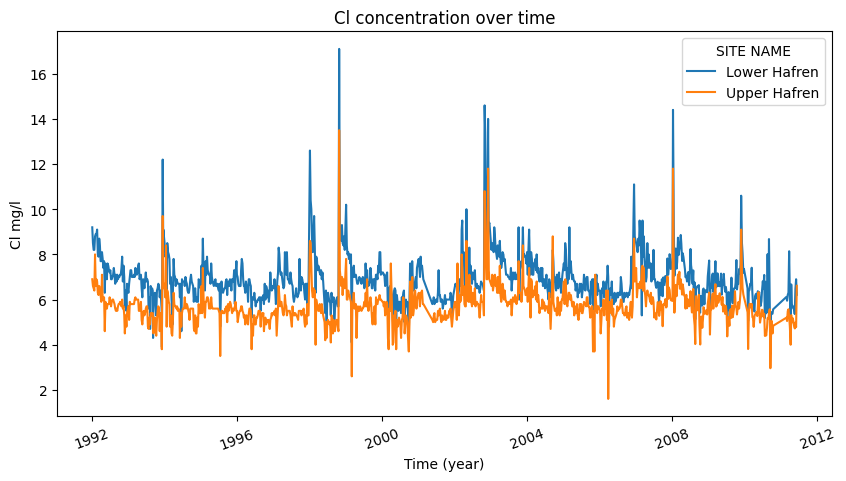

In [18]:
# visualization

plt.figure(figsize=(10,5))

g = sns.lineplot(
    data=df1,
    x="date_time",             # the time column: replace with yours
    y="Cl mg/l",          # one column name as text, not a list
    hue="SITE NAME",      # one line per site
)

plt.xlabel("Time (year)")
plt.ylabel("Cl mg/l")
plt.title("Cl concentration over time")
plt.xticks(rotation=20)   # avoid overlapping labels
plt.show()

### Activity 1: Discussion and Conclusions

*Use this Section to discuss your results and write down your conclusions*



* Cl concentration at Lower Hafren is generally higher than at Upper Hafren
  (mean X vs Y mg/l).
* As chloride is conserved, the difference is likely due to higher evapotranspiration and/or greater dry deposition in the lower catchment (Lower Hafren) than that of Upper Hafren.
* The highest value (around 17 mg/l, Lower Hafren) occurs in 1998, and the lowest (around 1.6 mg/l, Upper Hafren) around 2006.



---

### Activity 2: Problem formulation

Solute transport is strongly affected by catchment wetness, because different processes are dominant at different flow conditions. For this reason, looking at concentration-discharge (C-Q) relationships can be very informative of these processes. How do solutes originating mainly within the soil (e.g. DOC, Al) behave compared to solutes originating mainly in the subsoil (e.g. Si, Ca)?

### Activity 2: Development

Suggested strategy:
- prepare a dataframe with a selection of solutes (at least DOC and Si). It is better to select data after 1991 since measurements at Upper Hafren were not active before. Make sure you also select a variable that represents flow (or log flow).
- plot timeseries of the different solutes
- show C-Q relationships for these solutes. It is good to either represent the flow in log scale or to directly select the log_flow variable.

In [26]:
# Start writing your code here

var_selection_2 = [
    "SITE NAME",
    "date_time",
    "Si mg/l",
    "DOC mg/l",
    "log_flow",
    ]  # selection of variables

# Create a boolean index to filter by location and time -> x
q_2 = (
    (df["SITE NAME"].isin(["Lower Hafren","Upper Hafren"])) &  # select 2 sites, give a true only for these 2 elements (other will receive false), & gives out other requirement
    (df["date_time"] >= '1991-12-31')  # select a temporal interval
)

df2 = df.loc[q_2,var_selection_2] # rows for which q is true, end up with db with site names
df2.head(2)  # show the dataframe


,SITE NAME,date_time,Si mg/l,DOC mg/l,log_flow
3610,Lower Hafren,1992-01-07 09:30:00,1.5,1.3,-0.484126
3611,Lower Hafren,1992-01-14 09:02:00,1.8,1.0,-0.920819


In [48]:
# load current database, add month variable, simplify datatime
df2["year"] = df2["date_time"].dt.year
df2["date_time"] = df2["date_time"].dt.round('d')
df2.head()

# make the table longer through melt() function
df2_long = pd.melt(
    df2,
    id_vars = ["SITE NAME", "date_time", "month", 'log_flow'],
    value_vars = ['Si mg/l', 'DOC mg/l']
)

# print the dataframe size
print("dataframe shape:", {df2_long.shape})
df2_long.head()

dataframe shape: {(3984, 6)}


,SITE NAME,date_time,month,log_flow,variable,value
0,Lower Hafren,1992-01-07,1,-0.484126,Si mg/l,1.50
1,Lower Hafren,1992-01-14,1,-0.920819,Si mg/l,1.80
2,Lower Hafren,1992-01-21,1,-1.221849,Si mg/l,1.95
3,Lower Hafren,1992-01-28,1,-1.356547,Si mg/l,2.00
4,Lower Hafren,1992-02-04,2,-0.505845,Si mg/l,1.50


<Figure size 1000x500 with 0 Axes>

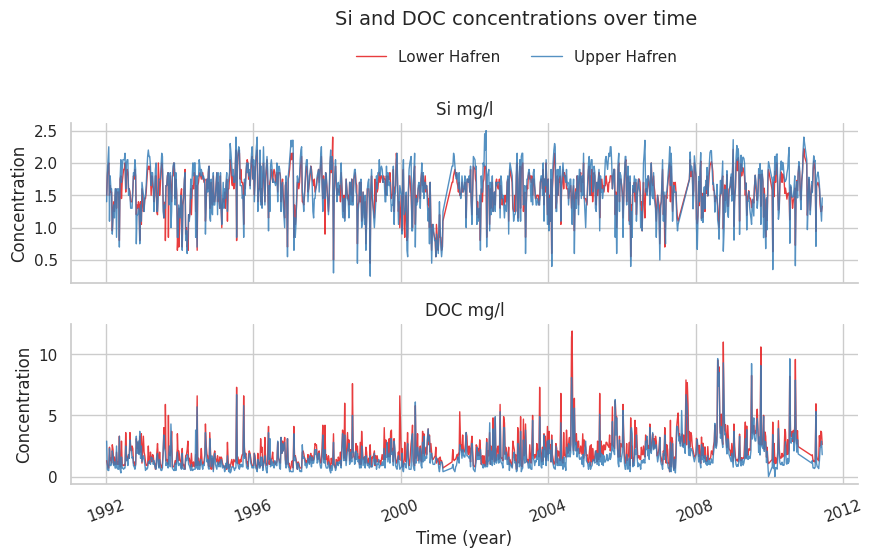

In [49]:
# visualizations: plot timeseries of the different solutes
plt.figure(figsize=(10,5))

# plot timeseries
solutes = ["Si mg/l", "DOC mg/l"]
subset = df2_long[df2_long["variable"].isin(solutes)]

g = sns.relplot(
    data=subset,
    x="date_time",
    y="value",
    row="variable",
    hue="SITE NAME",
    kind="line",
    facet_kws={"sharey": False, "sharex": True},
    height=2.6,
    aspect=3.5,
    linewidth=1,
    alpha=0.85,
    palette="Set1",
)

# short panel titles: just the solute name
g.set_titles(row_template="{row_name}")

# axis labels: units are already in the panel titles
g.set_axis_labels("Time (year)", "Concentration")

# rotate the date labels on every panel
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=20)

# legend on top, outside the data
sns.move_legend(g, "upper center", bbox_to_anchor=(0.5, 1.02),
                ncol=2, title=None, frameon=False)

g.figure.suptitle("Si and DOC concentrations over time", y=1.07, fontsize=14)
g.tight_layout()
plt.show()

A C-Q relationship plots concentration (C) against discharge (Q, stream flow). It shows whether a solute is diluted by high flow (C falls as Q rises), flushed out (C rises), or chemostatic (C stays roughly constant). Q varies over orders of magnitude, hence the log scale.

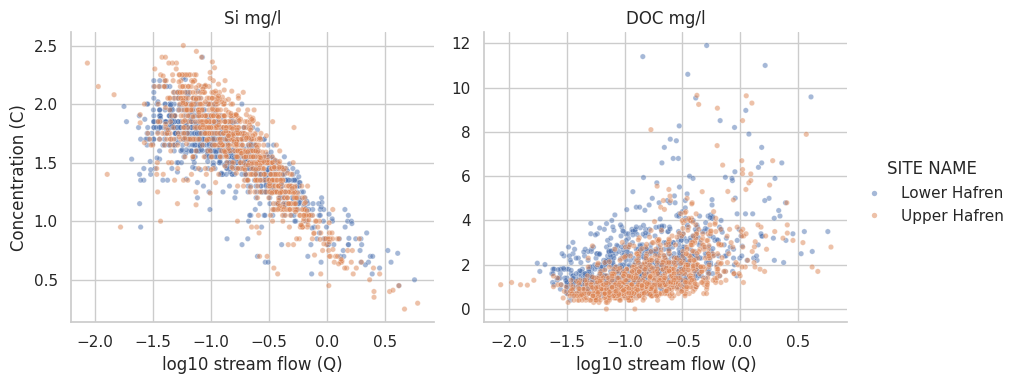

In [50]:
# Visualization: C-Q Relationship

sns.set_theme(style="whitegrid")

g = sns.relplot(
    data=df2_long,
    x="log_flow",
    y="value",
    col="variable",            # one panel per solute
    hue="SITE NAME",
    kind="scatter",
    facet_kws={"sharey": False, "sharex": True},
    height=4,
    aspect=1.1,
    s=15,
    alpha=0.5,
)
g.set_titles(col_template="{col_name}")
g.set_axis_labels("log10 stream flow (Q)", "Concentration (C)")
plt.show()

### Activity 2: Discussion and Conclusions

*Use this Section to discuss your results and write down your conclusions*

---

### Activity 3: problem formulation

The interplay between groundwater and soil water contributions to streamflow is one of the major causes of changes in solute concentration. Some solutes like Si are particularly helpful to quantify such contributions. If we make the assumption that, for a given solute, soil water and groundwater concentrations are rather constant (and if we can estimate them), then the groundwater contribution can be estimated through a simple linear mixing of the two sources, as we've seen in class. Based on the Si data, what is the contribution of groundwater to streamflow?

### Activity 3: development

Suggested strategy:
- prepare a dataframe with Si concentrations at the two sites. For convenience, let's work with the Lower Hafren data only
- make an assumption on the Si concentration in soil water and groundwater. Hint: define these concentrations based on the timeseries you produced in the second activity: typical high concentrations in stream water can be representative of the groundwater concentration, and typical low concentrations in stream water can be representative of the soil water concentration.
- create a new variable in the dataframe that implements the linear mixing formula

In [ ]:
# Start writing your code here



### Activity 3: Discussion and Conclusions

*Use this Section to discuss your results and write down your conclusions*